# Battery dispatch and electricity cost

Can day-ahead forecasts reduce simulated electricity costs for the Ausgrid households? Compare no battery, a battery scheduled with weekly persistence, and a battery scheduled with the validation-selected forecast. All three are scored on identical held-out household-days.

## Decision and replay

The [scenario](../config/scenario.json) uses illustrative Sydney weekday peak prices, a flat export credit, and a 10 kWh battery. The [scheduler](../src/battery_dispatch.py) minimizes forecast energy charges on a 0.5 kWh grid with a penalty for missing the 5 kWh end-of-day target. It plans before delivery and follows the planned charge levels as the current meter reading permits. Charge and discharge limits, conversion losses, and the prohibition on battery export apply to both planning and replay.

Charge carries between successive scored days and begins at 5 kWh after a gap. The cost comparison values any change in stored energy at the off-peak replenishment rate. The reported terminal-target count shows how often the causal replay achieves 5 kWh.

## Generate a 24-hour schedule

This cell defaults to tomorrow in Sydney. Set `meter_csv` to a current household meter file in the processed Ausgrid format. If no current file is supplied, the notebook explains why a live schedule is unavailable and shows a clearly labeled illustration on tomorrow’s timeline using a historical meter profile. Set the household ID and expected midnight charge for your home. See the [input requirements](../README.md#generate-a-schedule-for-a-date).

The upper panel shows the forecasts. Green bars charge the battery, purple bars supply the home, and gaps are idle. The power-supplied panel shows planned grid imports and battery discharge. Grid imports can also charge the battery. The bottom panel shows planned energy at each half-hour boundary.

No current meter file supplied for 29 November 2026 (Sydney).
Illustration only. Uses a July 2012 meter profile and the requested date’s tariff window.


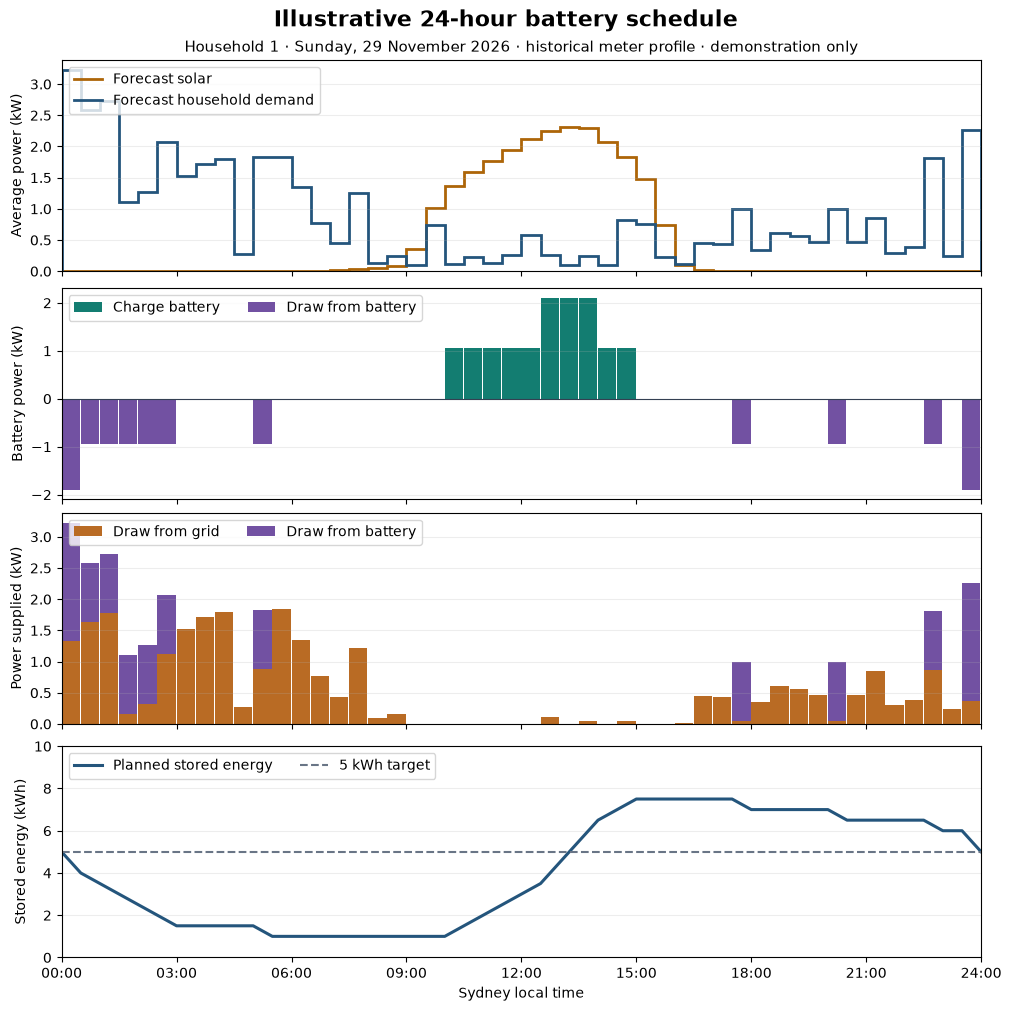

In [1]:
import sys
from datetime import date, datetime, timedelta
from pathlib import Path

import matplotlib.pyplot as plt

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
sys.path.insert(0, str(root / "src"))
from plot_schedule import schedule_figure
from weekly_baseline import SYDNEY

delivery_date = datetime.now(SYDNEY).date() + timedelta(days=1)
household = "1"
starting_kwh = 5.0
meter_csv = None  # Set to Path("/path/to/current_meter.csv") for an upcoming date.
forecast_method = "weekly_persistence"  # Or "validated_model"

if meter_csv is None:
    print(f"No current meter file supplied for {delivery_date:%d %B %Y} (Sydney).")
    print("Illustration only. Uses a July 2012 meter profile and the requested date’s tariff window.")
    sample = root / "data/sample/ausgrid_sample.csv"
    schedule_figure(delivery_date, "1", starting_kwh, sample, demo_profile_date=date(2012, 7, 23))
    plt.show()
else:
    try:
        schedule_figure(delivery_date, household, starting_kwh, Path(meter_csv), forecast_method)
    except (OSError, ValueError) as error:
        print(f"Schedule unavailable for {delivery_date}: {error}")
    else:
        plt.show()

## Check one dispatch decision

In this controlled case, the home exports solar at midday and imports during the expensive evening window. The forecast equals the simulated meter readings, so this illustrates the scheduling mechanics before introducing forecast error in the holdout.

In [2]:
import json
import sys
from datetime import date
from pathlib import Path

import numpy as np

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
sys.path.insert(0, str(root / "src"))
from battery_dispatch import BatteryDispatch

battery = BatteryDispatch(json.loads((root / "config/scenario.json").read_text()))
rates, _ = battery.rates(date(2012, 7, 2))
net = np.zeros((1, 48))
net[:, 22:27] = -1.5
net[:, 34:38] = 1.5
cost, terminal, throughput = battery.replay(net, net, np.array([battery.initial]), rates)
assert terminal[0] == battery.initial
assert cost[0] < battery.cost(net, rates).sum()
print(f"Without battery: AUD {battery.cost(net, rates).sum():.2f}")
print(f"With battery: AUD {cost[0]:.2f}, ending at {battery.states[terminal[0]]:.1f} kWh")

Without battery: AUD 2.35
With battery: AUD 0.55, ending at 5.0 kWh


In [3]:
import matplotlib.pyplot as plt
import pandas as pd

report = json.loads((root / "results/full_implementation.json").read_text())
dispatch = report["test"]["dispatch"]
model = report["selected_ml_model"]
strategies = ["weekly_persistence", model]
table = pd.DataFrame({name: dispatch[name] for name in strategies}).T
table.loc["no_battery", ["meter_cost_aud", "inventory_adjusted_cost_aud"]] = dispatch["no_battery_cost_aud"]
display(table.round(2))
print(f"{dispatch['households']} homes and {dispatch['household_days']:,} scored household-days")

,meter_cost_aud,days_ending_at_target_soc,inventory_adjusted_cost_aud,savings_aud,median_household_savings_aud,battery_ac_throughput_kwh
weekly_persistence,472760.57,59923.0,472377.04,27848.27,72.48,485151.26
gradient_boosting,472460.33,61529.0,472175.49,28049.82,70.28,412799.67
no_battery,500225.31,NaN,500225.31,NaN,NaN,NaN


300 homes and 106,585 scored household-days


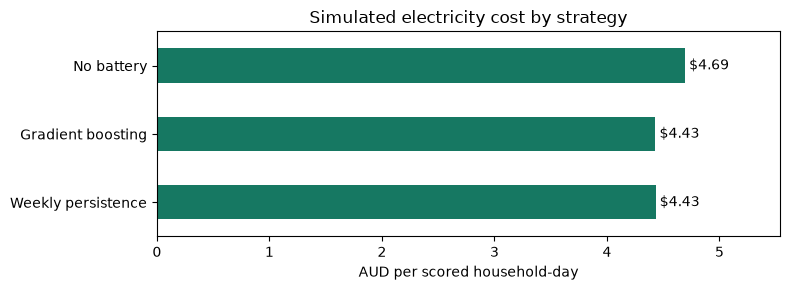

In [4]:
costs = table["inventory_adjusted_cost_aud"] / dispatch["household_days"]
costs.index = costs.index.str.replace("_", " ").str.capitalize()
ax = costs.plot.barh(figsize=(8, 3.0), color="#167862")
ax.set(xlabel="AUD per scored household-day", title="Simulated electricity cost by strategy")
ax.bar_label(ax.containers[0], fmt="$%.2f", padding=3)
ax.set_xlim(0, costs.max() * 1.18)
plt.tight_layout()
plt.show()

## Paired uncertainty check

For each scored Sydney date, compare the two battery strategies on the same households. The bootstrap resamples consecutive blocks of up to 14 scored dates, keeping the households for each date together. The interval is a sensitivity check for this cohort and illustrative scenario. Long seasonal dependence and new households can contribute uncertainty beyond this interval. A positive difference favors the fitted forecast.

In [5]:
difference = dispatch["ml_vs_persistence_savings_aud_per_household_day"]
low, high = dispatch["ml_vs_persistence_block_bootstrap_95pct"]
print(f"Fitted forecast savings vs. persistence: AUD {difference:+.4f} per household-day")
print(f"95% block-bootstrap interval: [{low:+.4f}, {high:+.4f}] AUD per household-day")

Fitted forecast savings vs. persistence: AUD +0.0019 per household-day
95% block-bootstrap interval: [-0.0049, +0.0075] AUD per household-day


## Pilot implications

Use representative current meter data and actual tariffs in a shadow pilot. Log the forecasts and schedules issued before delivery. Track forecast errors, realized energy charges, peak imports, battery throughput, and deviations from the planned charge level. Compare the forecast scheduler with persistence before connecting to hardware. Include battery purchase costs, degradation, and fixed charges in an investment decision.

Both battery strategies reduced simulated cost relative to no battery. The estimated cost advantage of gradient boosting over persistence was small and the paired interval included zero. This cohort and tariff provide no clear evidence that the better forecast needs to replace the simpler benchmark.